In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
image_folder = Path(
    r""C:\academics\codes\DSIP\input""
)

image_paths = [
    image_folder / f"{i}.jpeg"
    for i in range(1, 6)
]

images = {}

for i, path in enumerate(image_paths, start=1):

    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise FileNotFoundError(f"Image not found: {path}")

    images[f"Image {i}"] = image

print("All five images loaded successfully!")

All five images loaded successfully!


In [ ]:
def frequency_filter(image, filter_mask):

    image_float = image.astype(np.float32)

    dft = np.fft.fft2(image_float)

    dft_shift = np.fft.fftshift(dft)

    filtered = dft_shift * filter_mask

    inverse_shift = np.fft.ifftshift(filtered)

    output = np.fft.ifft2(inverse_shift)

    output = np.abs(output)

    return np.clip(output, 0, 255).astype(np.uint8)

In [ ]:
def frequency_distance(shape):

    rows, cols = shape

    center_row = rows // 2
    center_col = cols // 2

    u = np.arange(rows) - center_row
    v = np.arange(cols) - center_col

    U, V = np.meshgrid(v, u)

    D = np.sqrt(U**2 + V**2)

    return D

In [7]:
def gaussian_lowpass(shape, cutoff):

    D = frequency_distance(shape)

    H = np.exp(-(D**2) / (2 * cutoff**2))

    return H

In [8]:
def butterworth_lowpass(shape, cutoff, order=2):

    D = frequency_distance(shape)

    H = 1 / (1 + (D / cutoff)**(2 * order))

    return H

In [9]:
gaussian_images = {}
butterworth_images = {}

for name, image in images.items():

    rows, cols = image.shape

    gaussian_mask = gaussian_lowpass(
        image.shape, cutoff=30
    )

    butterworth_mask = butterworth_lowpass(
        image.shape, cutoff=30, order=2
    )

    gaussian_images[name] = frequency_filter(
        image, gaussian_mask
    )

    butterworth_images[name] = frequency_filter(
        image, butterworth_mask
    )

print("Gaussian and Butterworth filtering completed!")

Gaussian and Butterworth filtering completed!


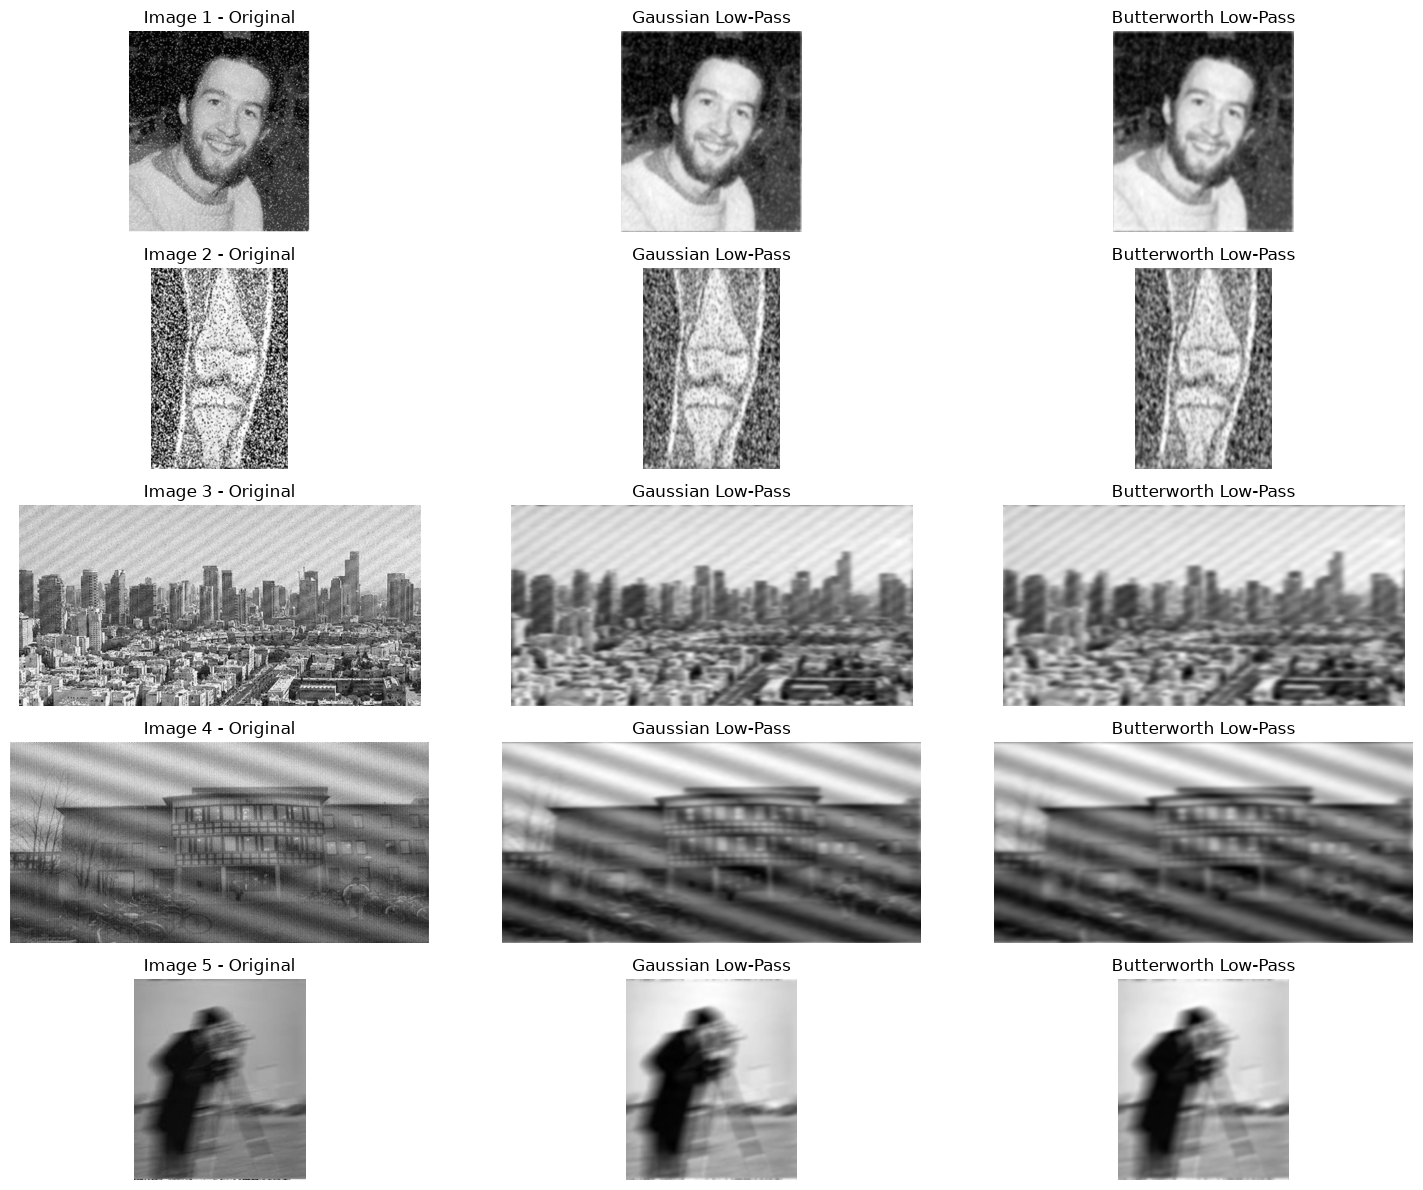

In [10]:
plt.figure(figsize=(15, 12))

for i, name in enumerate(images):

    plt.subplot(5, 3, 3 * i + 1)
    plt.imshow(images[name], cmap="gray")
    plt.title(name + " - Original")
    plt.axis("off")

    plt.subplot(5, 3, 3 * i + 2)
    plt.imshow(gaussian_images[name], cmap="gray")
    plt.title("Gaussian Low-Pass")
    plt.axis("off")

    plt.subplot(5, 3, 3 * i + 3)
    plt.imshow(butterworth_images[name], cmap="gray")
    plt.title("Butterworth Low-Pass")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def highboost_filter(image, cutoff=30, boost=1.5):

    H_lp = gaussian_lowpass(image.shape, cutoff)

    H_hb = 1 + boost * (1 - H_lp)

    return frequency_filter(image, H_hb)

In [12]:
gaussian_sharpened = {}
butterworth_sharpened = {}

for name in images:

    gaussian_sharpened[name] = highboost_filter(
        gaussian_images[name],
        cutoff=30,
        boost=1.5
    )

    butterworth_sharpened[name] = highboost_filter(
        butterworth_images[name],
        cutoff=30,
        boost=1.5
    )

print("High-boost sharpening completed!")

High-boost sharpening completed!


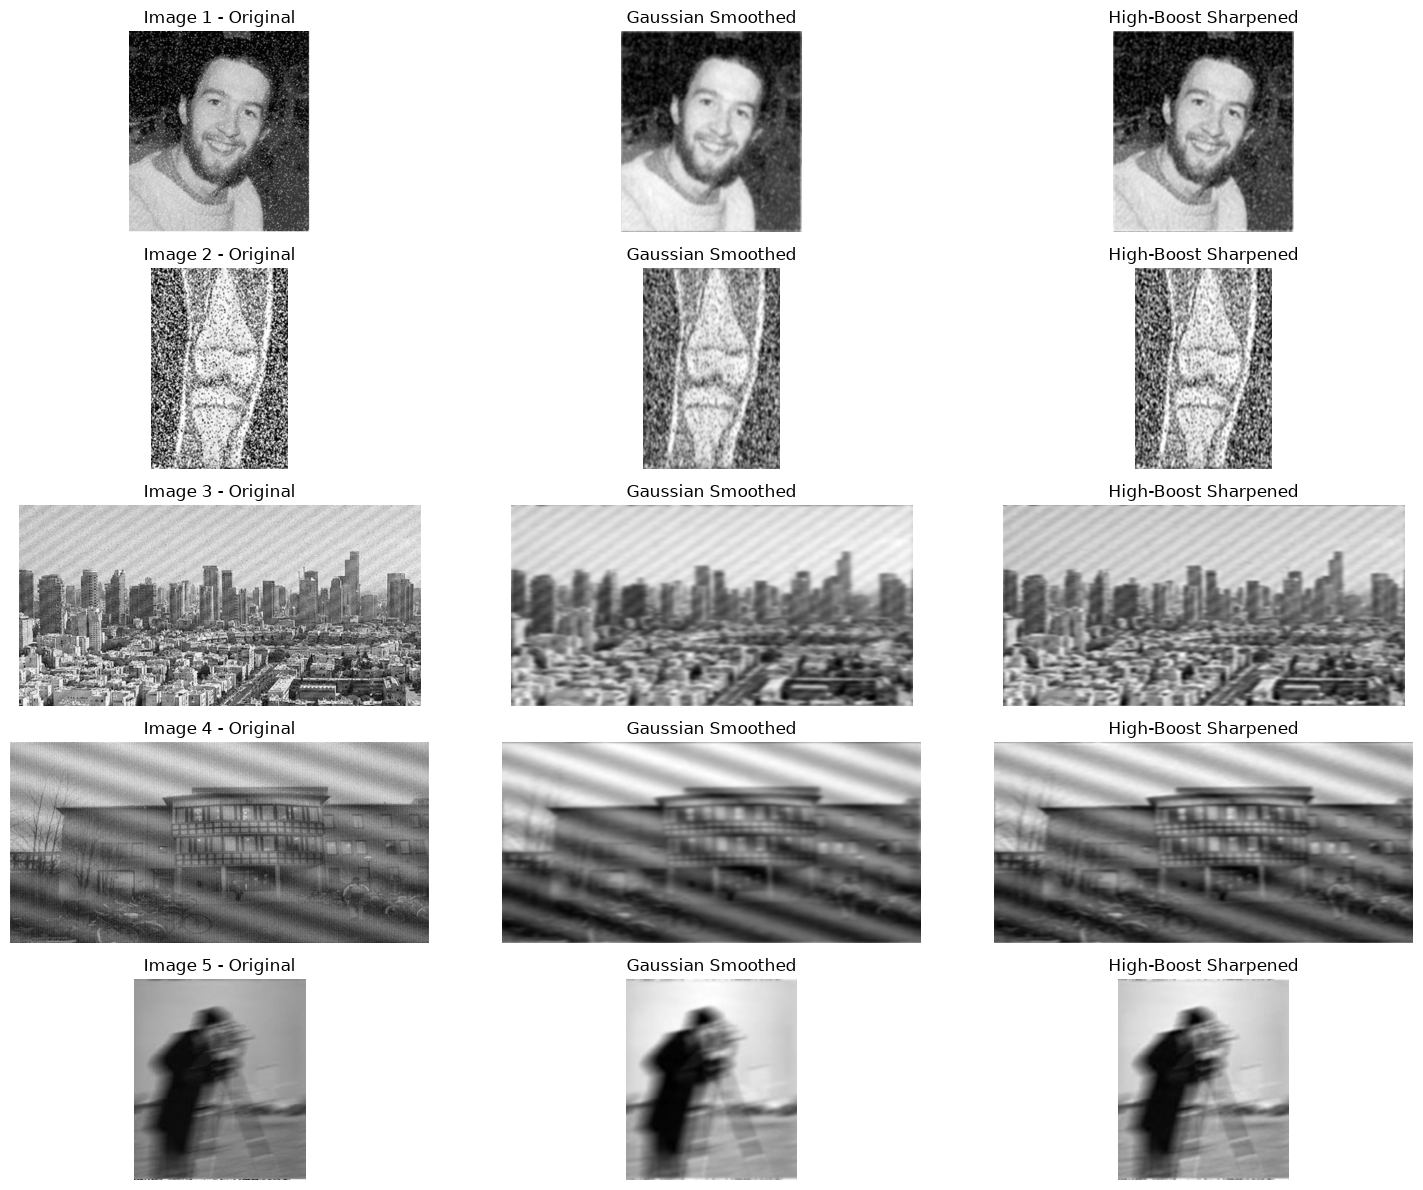

In [13]:
plt.figure(figsize=(15, 12))

for i, name in enumerate(images):

    plt.subplot(5, 3, 3 * i + 1)
    plt.imshow(images[name], cmap="gray")
    plt.title(name + " - Original")
    plt.axis("off")

    plt.subplot(5, 3, 3 * i + 2)
    plt.imshow(gaussian_images[name], cmap="gray")
    plt.title("Gaussian Smoothed")
    plt.axis("off")

    plt.subplot(5, 3, 3 * i + 3)
    plt.imshow(gaussian_sharpened[name], cmap="gray")
    plt.title("High-Boost Sharpened")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
boundary_images = {}

for name, image in gaussian_sharpened.items():

    median_value = np.median(image)

    lower_threshold = int(max(0, 0.66 * median_value))
    upper_threshold = int(min(255, 1.33 * median_value))

    edges = cv2.Canny(
        image,
        lower_threshold,
        upper_threshold
    )

    boundary_images[name] = edges

print("Boundary extraction completed!")

Boundary extraction completed!


In [15]:
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

clean_boundaries = {}

for name, image in boundary_images.items():

    closed = cv2.morphologyEx(
        image,
        cv2.MORPH_CLOSE,
        kernel
    )

    cleaned = cv2.morphologyEx(
        closed,
        cv2.MORPH_OPEN,
        kernel
    )

    clean_boundaries[name] = cleaned

print("Clean binary boundary images generated!")

Clean binary boundary images generated!


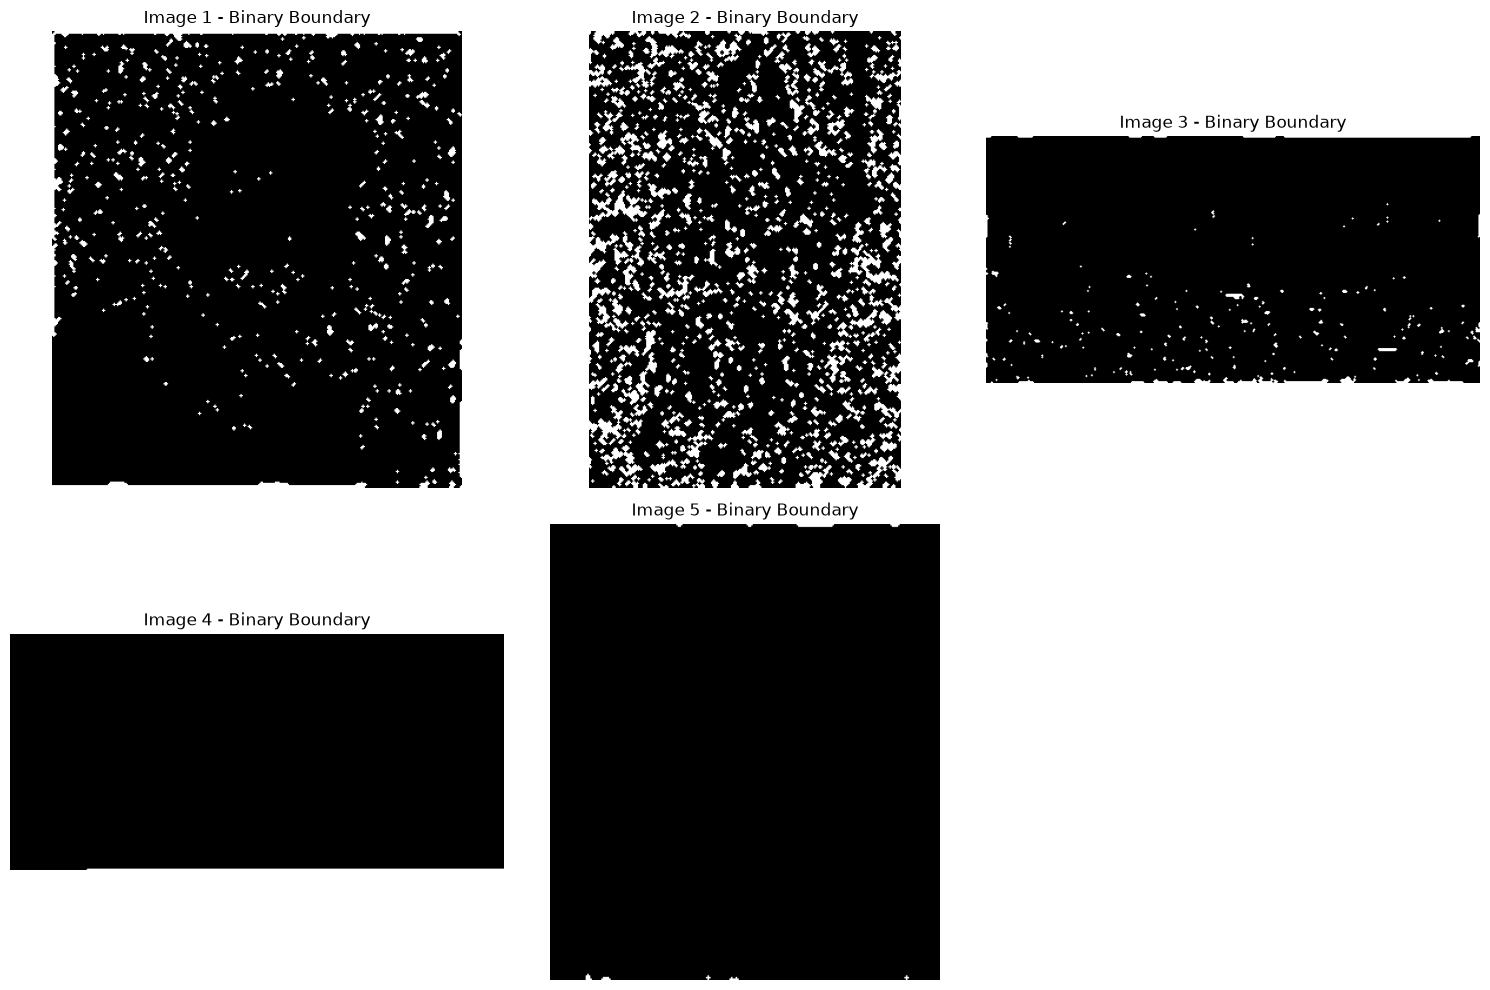

In [16]:
plt.figure(figsize=(15, 10))

for i, name in enumerate(clean_boundaries):

    plt.subplot(2, 3, i + 1)
    plt.imshow(clean_boundaries[name], cmap="gray")
    plt.title(name + " - Binary Boundary")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
def calculate_metrics(image, edges):

    mean_value = np.mean(image)

    std_value = np.std(image)

    sharpness = cv2.Laplacian(
        image, cv2.CV_64F
    ).var()

    edge_percentage = (
        np.count_nonzero(edges) / edges.size
    ) * 100

    return {
        "Mean Intensity": round(mean_value, 2),
        "Standard Deviation": round(std_value, 2),
        "Laplacian Variance": round(sharpness, 2),
        "Edge Percentage": round(edge_percentage, 2)
    }


metrics = []

for name in images:

    versions = {
        "Original": images[name],
        "Gaussian": gaussian_images[name],
        "Butterworth": butterworth_images[name],
        "High-Boost": gaussian_sharpened[name]
    }

    for method, image in versions.items():

        edges = cv2.Canny(image, 100, 200)

        result = calculate_metrics(image, edges)

        result["Image"] = name
        result["Method"] = method

        metrics.append(result)

metrics_df = pd.DataFrame(metrics)

display(metrics_df)

,Mean Intensity,Standard Deviation,Laplacian Variance,Edge Percentage,Image,Method
0,104.73,73.94,1456.44,18.85,Image 1,Original
1,104.22,69.37,34.23,1.45,Image 1,Gaussian
2,104.23,69.63,23.06,0.94,Image 1,Butterworth
3,103.75,71.10,98.60,3.45,Image 1,High-Boost
4,154.38,71.11,4628.95,33.93,Image 2,Original
5,153.88,51.98,115.51,16.36,Image 2,Gaussian
6,153.88,51.34,51.80,8.81,Image 2,Butterworth
7,153.38,59.68,425.86,27.23,Image 2,High-Boost
8,155.08,57.34,4159.71,20.33,Image 3,Original
9,154.57,46.82,21.76,1.60,Image 3,Gaussian


In [18]:
output_folder = image_folder / "Processed_Images"

folders = {
    "Gaussian": gaussian_images,
    "Butterworth": butterworth_images,
    "Gaussian_HighBoost": gaussian_sharpened,
    "Butterworth_HighBoost": butterworth_sharpened,
    "Boundary_Maps": boundary_images,
    "Clean_Boundaries": clean_boundaries
}

for folder_name, image_set in folders.items():

    save_folder = output_folder / folder_name
    save_folder.mkdir(parents=True, exist_ok=True)

    for name, image in image_set.items():

        filename = name.replace(" ", "_") + ".png"

        cv2.imwrite(
            str(save_folder / filename),
            image
        )

metrics_df.to_csv(
    output_folder / "Performance_Comparison.csv",
    index=False
)

print("All processed images and comparison results saved!")

All processed images and comparison results saved!
